# Finding the Optimal Ask-Bid Spread for a Market Maker

In [1]:
import random
import math
import statistics
import matplotlib.pyplot as plt
import numpy as np

def improved_market_maker(Spreads,seed,volatility=.2,trade_steps=1000,spread_steps=100,customer_uncertainty=.8,informed_fraction=.1,informed_trade_probability=.65):
    rng = random.Random(seed)
    SpreadsProfit = []
    AvgTrades = []
    SpreadsLossRate = []
    PnlStdevs = []
    for spread in Spreads: 
        total_profit = 0.0
        total_trades = 0
        losses = 0
        run_pnls = []
        for i in range(spread_steps):
            fair_price = 100.0
            inventory = 0
            cash = 0.0
            max_inventory = 10
            order_flow_bias = .4
            arrival_sensitivity = .7
            trades = 0
            pnl = 0
            transaction_cost = .02
            for t in range(trade_steps):
                price_change = rng.gauss(0, volatility)

                bid = fair_price - spread / 2
                ask = fair_price + spread / 2

                arrival_prob = math.exp(-arrival_sensitivity * spread)
                if rng.random() < arrival_prob:
                    if rng.random() < informed_fraction:
                        if price_change > 0:
                            if rng.random() < informed_trade_probability:
                                buy_probability = (.5 + order_flow_bias)
                            else:
                                buy_probability = (.5 - order_flow_bias)
                        elif price_change <0:
                            if rng.random() < informed_trade_probability:
                                buy_probability = (.5 - order_flow_bias)
                            else:
                                buy_probability = (.5 + order_flow_bias)
                        else:
                            buy_probability = .5
                        if rng.random() < buy_probability and inventory > -max_inventory:
                            inventory -= 1
                            cash += ask - transaction_cost
                            trades += 1
                        elif rng.random() >= buy_probability and inventory < max_inventory:
                            inventory += 1
                            cash -= bid + transaction_cost
                            trades += 1
                    else:
                        customer_min_surplus = .05
                        customer_value = fair_price + rng.gauss(0, customer_uncertainty)
                        buy_surplus = customer_value - ask
                        sell_surplus = bid - customer_value
                        if buy_surplus > customer_min_surplus and buy_surplus >= sell_surplus and inventory > -max_inventory:
                            inventory -= 1
                            cash += ask - transaction_cost
                            trades += 1
                        elif sell_surplus > customer_min_surplus and sell_surplus > buy_surplus and inventory < max_inventory:
                            inventory += 1
                            cash -= bid + transaction_cost
                            trades += 1
                fair_price += price_change
            pnl += cash + inventory * fair_price
            run_pnls.append(pnl)
            total_profit += pnl

            if pnl < 0:
                losses += 1
            
            total_trades += trades
        average_trades = total_trades / spread_steps
        loss_rate = losses / spread_steps
        SpreadsLossRate.append(loss_rate)
        SpreadsProfit.append(total_profit / spread_steps)
        AvgTrades.append(average_trades)
        PnlStdevs.append(statistics.stdev(run_pnls))
    return SpreadsProfit, AvgTrades, SpreadsLossRate, PnlStdevs

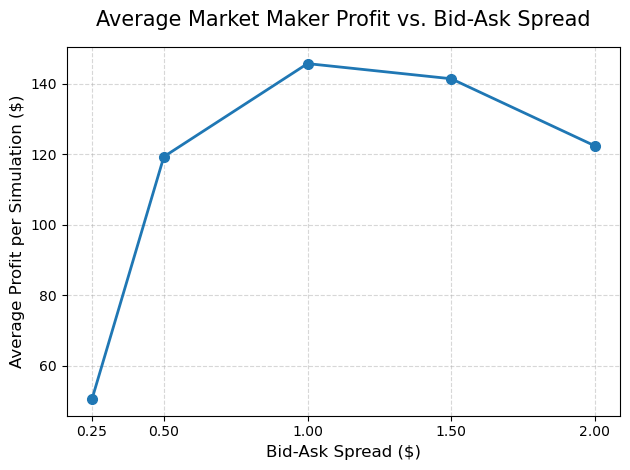

In [3]:
# Start with a simple plot of average profit vs. spread

Spreads = [.25,.5,1.0,1.5,2.0]
SpreadsProfit, AvgTrades, SpreadsLossRate, PnlStdevs = improved_market_maker(Spreads, seed=42, volatility=.2,customer_uncertainty=.8,informed_fraction=.5,informed_trade_probability=.65)
plt.plot(Spreads, SpreadsProfit, marker='o',markersize=7,linewidth=2)
plt.title('Average Market Maker Profit vs. Bid-Ask Spread',fontsize=15,pad=15)
plt.xlabel('Bid-Ask Spread ($)', fontsize=12)
plt.ylabel('Average Profit per Simulation ($)', fontsize=12)

plt.xticks(Spreads)
plt.grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

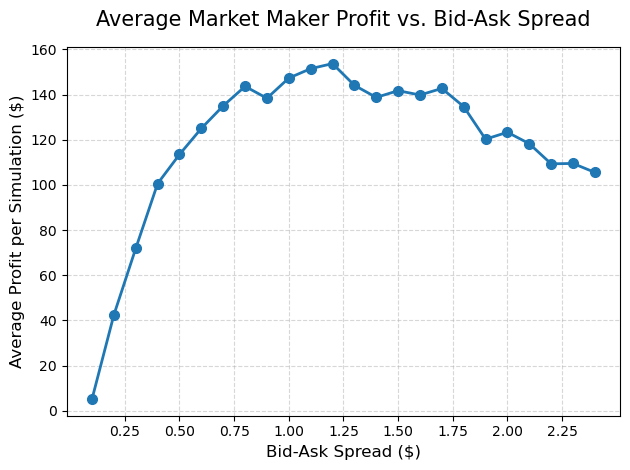

In [4]:
#Try a longer list of spreads to see if we can get a better approxiation

Spreads2 = [i/10 for i in range(1,25,1)]
SpreadsProfit, AvgTrades, SpreadsLossRate, PnlStdevs = improved_market_maker(Spreads2, seed=42, volatility=.2,customer_uncertainty=.8,informed_fraction=.5,informed_trade_probability=.65)
plt.plot(Spreads2, SpreadsProfit, marker='o',markersize=7,linewidth=2)
plt.title('Average Market Maker Profit vs. Bid-Ask Spread',fontsize=15,pad=15)
plt.xlabel('Bid-Ask Spread ($)', fontsize=12)
plt.ylabel('Average Profit per Simulation ($)', fontsize=12)

plt.xticks([i/4 for i in range(1,10,1)])
plt.grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

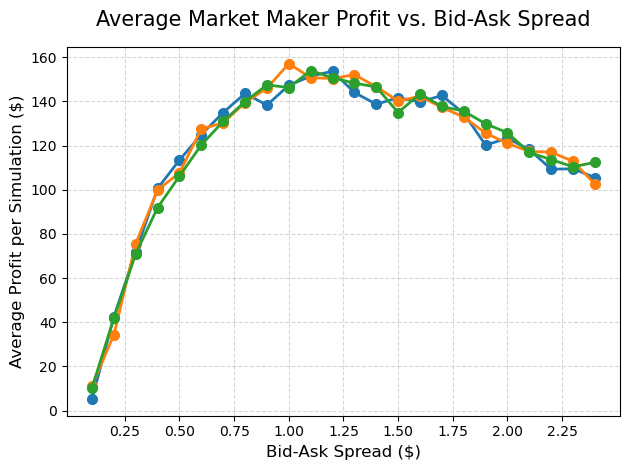

In [18]:
# It is clear that the seed does not have an impact

Spreads2 = [i/10 for i in range(1,25,1)]
SpreadsProfit, AvgTrades, SpreadsLossRate, PnlStdevs = improved_market_maker(Spreads2, seed=42, volatility=.2,customer_uncertainty=.8,informed_fraction=.5,informed_trade_probability=.65)
plt.plot(Spreads2, SpreadsProfit, marker='o',markersize=7,linewidth=2)
SpreadsProfit, AvgTrades, SpreadsLossRate, PnlStdevs = improved_market_maker(Spreads2, seed=101, volatility=.2,customer_uncertainty=.8,informed_fraction=.5,informed_trade_probability=.65)
plt.plot(Spreads2, SpreadsProfit, marker='o',markersize=7,linewidth=2)
SpreadsProfit, AvgTrades, SpreadsLossRate, PnlStdevs = improved_market_maker(Spreads2, seed=23, volatility=.2,customer_uncertainty=.8,informed_fraction=.5,informed_trade_probability=.65)
plt.plot(Spreads2, SpreadsProfit, marker='o',markersize=7,linewidth=2)
plt.title('Average Market Maker Profit vs. Bid-Ask Spread',fontsize=15,pad=15)
plt.xlabel('Bid-Ask Spread ($)', fontsize=12)
plt.ylabel('Average Profit per Simulation ($)', fontsize=12)

plt.xticks([i/4 for i in range(1,10,1)])
plt.grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

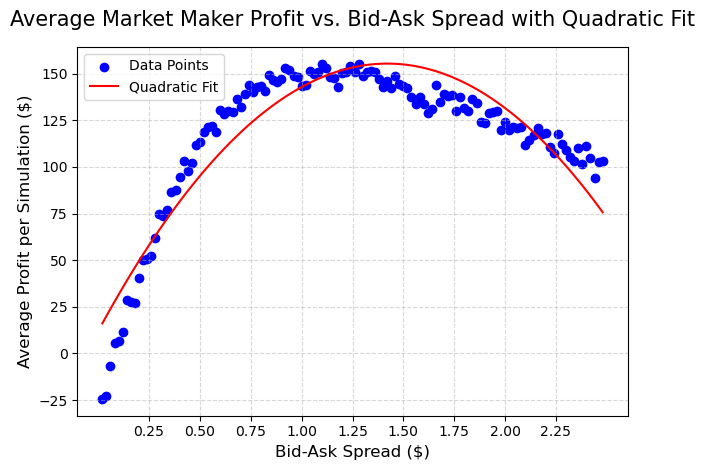

In [5]:
#Try a quadratic regression for approxiamtion of optimal spread
Spreads2 = [i/50 for i in range(1,125,1)]
SpreadsProfit, AvgTrades, SpreadsLossRate, PnlStdevs = improved_market_maker(Spreads2, seed=42, volatility=.2,customer_uncertainty=.8,informed_fraction=.5,informed_trade_probability=.65)

coefficients = np.polyfit(Spreads2, SpreadsProfit, 2)
a,b,c = coefficients

spread_fit = np.linspace(min(Spreads2), max(Spreads2), 100)
profit_fit = a * spread_fit**2 + b * spread_fit + c

plt.scatter(Spreads2, SpreadsProfit, color='blue', label='Data Points')
plt.plot(spread_fit, profit_fit, color='red', label='Quadratic Fit')
plt.title('Average Market Maker Profit vs. Bid-Ask Spread with Quadratic Fit', fontsize=15, pad=15)
plt.xlabel('Bid-Ask Spread ($)', fontsize=12)
plt.ylabel('Average Profit per Simulation ($)', fontsize=12)
plt.xticks([i/4 for i in range(1,10,1)])
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend()
plt.tight_layout()
plt.show()

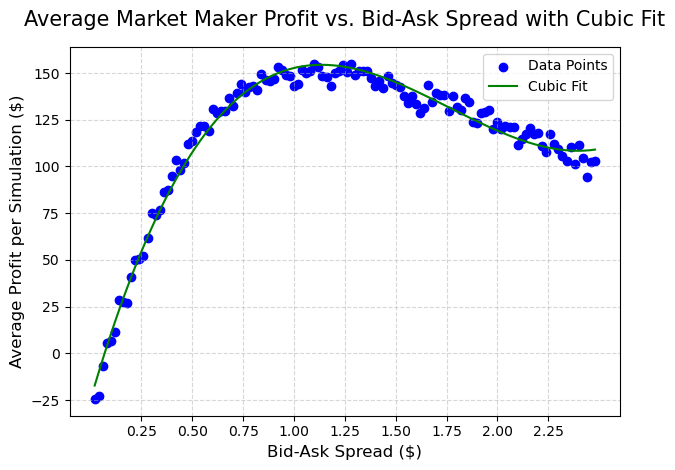

In [6]:
#Now try a cubic fit

coefficients_cubic = np.polyfit(Spreads2, SpreadsProfit, 3)
a_cubic, b_cubic, c_cubic, d_cubic = coefficients_cubic

spread_fit_cubic = np.linspace(min(Spreads2), max(Spreads2), 100)
profit_fit_cubic = a_cubic * spread_fit_cubic**3 + b_cubic * spread_fit_cubic**2 + c_cubic * spread_fit_cubic + d_cubic

plt.scatter(Spreads2, SpreadsProfit, color='blue', label='Data Points')
plt.plot(spread_fit_cubic, profit_fit_cubic, color='green', label='Cubic Fit')
plt.title('Average Market Maker Profit vs. Bid-Ask Spread with Cubic Fit', fontsize=15, pad=15)
plt.xlabel('Bid-Ask Spread ($)', fontsize=12)
plt.ylabel('Average Profit per Simulation ($)', fontsize=12)
plt.xticks([i/4 for i in range(1,10,1)])
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend()
plt.tight_layout()
plt.savefig('market_maker_profit_vs_spread_cubic_fit.png', dpi=300)
plt.show()

In [30]:
#That looks a lot better. Now let's find the optimal spread using the cubic fit.

optimal_spread_cubic = spread_fit_cubic[np.argmax(profit_fit_cubic)]
print(f"The optimal spread based on the cubic fit is approximately: {optimal_spread_cubic}")

The optimal spread based on the cubic fit is approximately: 1.1381818181818182


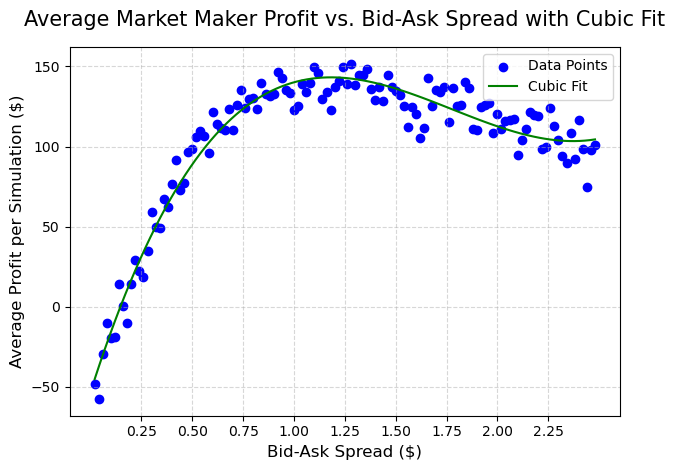

In [31]:
# So 1.14 is the optimal spread for this set of parameters. Let's see how the average trades change with different volatility levels.

Spreads2 = [i/50 for i in range(1,125,1)]
SpreadsProfit, AvgTrades, SpreadsLossRate, PnlStdevs = improved_market_maker(Spreads2, seed=42, volatility=.5,customer_uncertainty=.8,informed_fraction=.5,informed_trade_probability=.65)

coefficients_cubic = np.polyfit(Spreads2, SpreadsProfit, 3)
a_cubic, b_cubic, c_cubic, d_cubic = coefficients_cubic

spread_fit_cubic = np.linspace(min(Spreads2), max(Spreads2), 100)
profit_fit_cubic = a_cubic * spread_fit_cubic**3 + b_cubic * spread_fit_cubic**2 + c_cubic * spread_fit_cubic + d_cubic

plt.scatter(Spreads2, SpreadsProfit, color='blue', label='Data Points')
plt.plot(spread_fit_cubic, profit_fit_cubic, color='green', label='Cubic Fit')
plt.title('Average Market Maker Profit vs. Bid-Ask Spread with Cubic Fit', fontsize=15, pad=15)
plt.xlabel('Bid-Ask Spread ($)', fontsize=12)
plt.ylabel('Average Profit per Simulation ($)', fontsize=12)
plt.xticks([i/4 for i in range(1,10,1)])
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend()
plt.tight_layout()
plt.show()

In [33]:
optimal_spread_cubic = spread_fit_cubic[np.argmax(profit_fit_cubic)]
print(f"The optimal spread based on the cubic fit for .5 volatility is approximately: {optimal_spread_cubic}")

The optimal spread based on the cubic fit for .5 volatility is approximately: 1.187878787878788


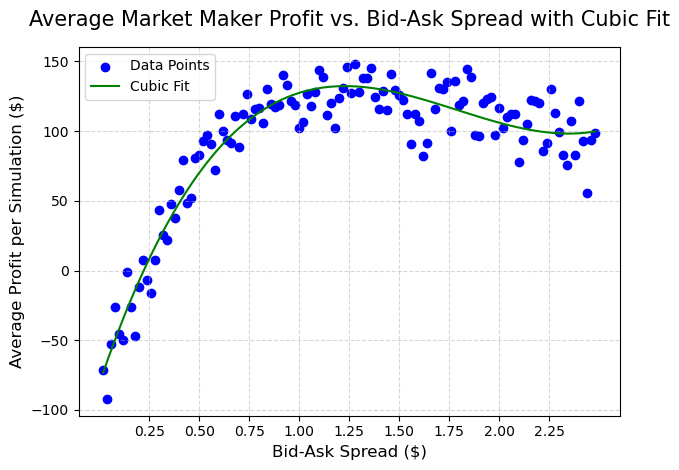

In [34]:
Spreads2 = [i/50 for i in range(1,125,1)]
SpreadsProfit, AvgTrades, SpreadsLossRate, PnlStdevs = improved_market_maker(Spreads2, seed=42, volatility=.8,customer_uncertainty=.8,informed_fraction=.5,informed_trade_probability=.65)

coefficients_cubic = np.polyfit(Spreads2, SpreadsProfit, 3)
a_cubic, b_cubic, c_cubic, d_cubic = coefficients_cubic

spread_fit_cubic = np.linspace(min(Spreads2), max(Spreads2), 100)
profit_fit_cubic = a_cubic * spread_fit_cubic**3 + b_cubic * spread_fit_cubic**2 + c_cubic * spread_fit_cubic + d_cubic

plt.scatter(Spreads2, SpreadsProfit, color='blue', label='Data Points')
plt.plot(spread_fit_cubic, profit_fit_cubic, color='green', label='Cubic Fit')
plt.title('Average Market Maker Profit vs. Bid-Ask Spread with Cubic Fit', fontsize=15, pad=15)
plt.xlabel('Bid-Ask Spread ($)', fontsize=12)
plt.ylabel('Average Profit per Simulation ($)', fontsize=12)
plt.xticks([i/4 for i in range(1,10,1)])
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend()
plt.tight_layout()
plt.show()

In [35]:
optimal_spread_cubic = spread_fit_cubic[np.argmax(profit_fit_cubic)]
print(f"The optimal spread based on the cubic fit for .5 volatility is approximately: {optimal_spread_cubic}")

The optimal spread based on the cubic fit for .5 volatility is approximately: 1.2375757575757576


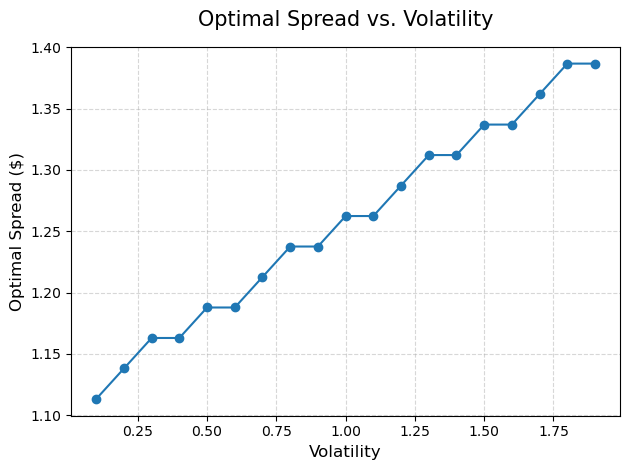

In [46]:
# Let's graph optimal spread vs. volatility to see how the optimal spread changes with different volatility levels.

volatility_levels = [i/10 for i in range(1,20)]
optimal_spreads = []
for i in volatility_levels:
    SpreadsProfit, AvgTrades, SpreadsLossRate, PnlStdevs = improved_market_maker(Spreads2, seed=42, volatility=i,customer_uncertainty=.8,informed_fraction=.5,informed_trade_probability=.65)
    coefficients_cubic = np.polyfit(Spreads2, SpreadsProfit, 3)
    a_cubic, b_cubic, c_cubic, d_cubic = coefficients_cubic
    spread_fit_cubic = np.linspace(min(Spreads2), max(Spreads2), 100)
    profit_fit_cubic = a_cubic * spread_fit_cubic**3 + b_cubic * spread_fit_cubic**2 + c_cubic * spread_fit_cubic + d_cubic
    optimal_spread = spread_fit_cubic[np.argmax(profit_fit_cubic)]
    optimal_spreads.append(optimal_spread)

plt.plot(volatility_levels, optimal_spreads, marker='o')
plt.title('Optimal Spread vs. Volatility', fontsize=15, pad=15)
plt.xlabel('Volatility', fontsize=12)
plt.ylabel('Optimal Spread ($)', fontsize=12)
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

In [47]:
#Very linear relationship, let's find a linear regression for this.

slope, intercept = np.polyfit(volatility_levels, optimal_spreads, 1)
linear_fit = [slope * x + intercept for x in volatility_levels]
linear_fit_equation = f"y = {slope:.4f}x + {intercept:.4f}"
print(f"Linear fit equation for optimal spread vs. volatility: {linear_fit_equation}")

Linear fit equation for optimal spread vs. volatility: y = 0.1500x + 1.1072


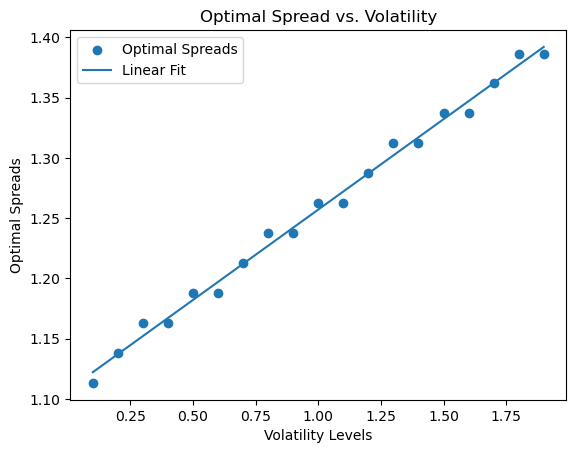

In [48]:
# This positive relationship makes sense, as higher volatility would require a higher spread to compensate for the increased risk
plt.scatter(volatility_levels, optimal_spreads, marker='o', label='Optimal Spreads')
plt.plot(volatility_levels, linear_fit, label='Linear Fit')
plt.xlabel('Volatility Levels')
plt.ylabel('Optimal Spreads')
plt.title('Optimal Spread vs. Volatility')
plt.legend()
plt.show()

In [58]:
# Now that we have an equation, let's test it's accuracy for predicting optimal spreads at different volatility levels

# Take vol = .25, .55, .75 and see how well the linear fit predicts the optimal spread
test_volatilities = [.25, .55, .75]
predicted_spreads = [slope * x + intercept for x in test_volatilities]
print(f"Predicted spreads for test volatilities {test_volatilities}: {predicted_spreads}")
for v in test_volatilities:
    SpreadsProfit, AvgTrades, SpreadsLossRate, PnlStdevs = improved_market_maker(Spreads2, seed=42, volatility=v,customer_uncertainty=.8,informed_fraction=.5,informed_trade_probability=.65)
    coefficients_cubic = np.polyfit(Spreads2, SpreadsProfit, 3)
    a_cubic, b_cubic, c_cubic, d_cubic = coefficients_cubic
    spread_fit_cubic = np.linspace(min(Spreads2), max(Spreads2), 100)
    profit_fit_cubic = a_cubic * spread_fit_cubic**3 + b_cubic * spread_fit_cubic**2 + c_cubic * spread_fit_cubic + d_cubic
    optimal_spread = spread_fit_cubic[np.argmax(profit_fit_cubic)]
    print(f"Actual optimal spread for volatility {v}: {optimal_spread}")

Predicted spreads for test volatilities [0.25, 0.55, 0.75]: [np.float64(1.1447208931419464), np.float64(1.1897097288676242), np.float64(1.219702286018076)]
Actual optimal spread for volatility 0.25: 1.1381818181818182
Actual optimal spread for volatility 0.55: 1.187878787878788
Actual optimal spread for volatility 0.75: 1.2127272727272729


In [9]:
#These are not perfect predictions, partially due to this seemingly piecewise linear relationship. We can still make a good approximating function based off this
def OptimalSpread(vol,seed = 42, customer_uncertainty=.8,informed_fraction=.5,informed_trade_probability=.65,spreads = [i/50 for i in range(1,125,1)]):
    Spreads2 = [i/50 for i in range(1,125,1)]
    SpreadsProfit, AvgTrades, SpreadsLossRate, PnlStdevs = improved_market_maker(Spreads2, seed=42, volatility=vol,customer_uncertainty=.8,informed_fraction=.5,informed_trade_probability=.65)
    coefficients_cubic = np.polyfit(spreads, SpreadsProfit, 3)
    a_cubic, b_cubic, c_cubic, d_cubic = coefficients_cubic
    spread_fit_cubic = np.linspace(min(spreads), max(Spreads2), 100)
    profit_fit_cubic = a_cubic * spread_fit_cubic**3 + b_cubic * spread_fit_cubic**2 + c_cubic * spread_fit_cubic + d_cubic
    optimal_spread = spread_fit_cubic[np.argmax(profit_fit_cubic)]
    return optimal_spread
